# Employee Attrition & Workforce Analytics

**Student Name:** TRIPTI

**Batch:** june batch Artificial Intelligence

**Internship:** BLEEP Internship

**Project:** Employee Attrition & Workforce Analytics

**Project Type:** Exploratory Data Analysis (EDA)

**Notebook:** Data Understanding & Exploratory Data Analysis


# Employee Attrition Prediction

## Project Overview

This project aims to predict whether an employee is likely to leave an organization using machine learning.

The dataset contains employee-related information such as age, job role, income, job satisfaction, overtime, years at the company, and other workplace-related factors.

The project includes exploratory data analysis (EDA), data preprocessing, machine learning model training, model evaluation, and interpretation of important factors associated with employee attrition.

## 1. Import Libraries and Load Dataset

We first import the required Python libraries and load the employee dataset into a Pandas DataFrame.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import sys
print(sys.executable)

C:\Users\tript\miniconda3\python.exe


In [4]:
df=pd.read_csv("C:/Users/tript/Downloads/PROJECTS/Employee-Attrition-Prediction/data/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 2. Understanding the Dataset

Before building a machine learning model, we inspect the dataset to understand its size, structure, data types, and available features.

In [6]:
df.shape


(1470, 35)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

### 2.1 Numerical Feature Summary

The `describe()` function provides statistical summaries of numerical features, including count, mean, standard deviation, minimum, maximum, and quartile values.

This helps us understand the distribution and range of numerical variables.

In [8]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### 2.2 Categorical Feature Summary

We examine the categorical variables to understand their unique values, most frequent categories, and their frequencies.

In [9]:
df.describe(include='object')

C:\Users\tript\AppData\Local\Temp\ipykernel_23436\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


### 2.3 Missing Value Analysis

We check for missing values in each column.

Missing values can cause problems during machine learning, so identifying them is an important preprocessing step.

In [10]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, distributions, relationships, and possible factors associated with employee attrition.

We will examine the target distribution, categorical features, and relationships between numerical variables.

In [11]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [12]:
df["Attrition"].value_counts(normalize=True) * 100


Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

### 3.1 Attrition Distribution

We examine the distribution of the target variable, `Attrition`, to understand how many employees stayed and how many left the organization.

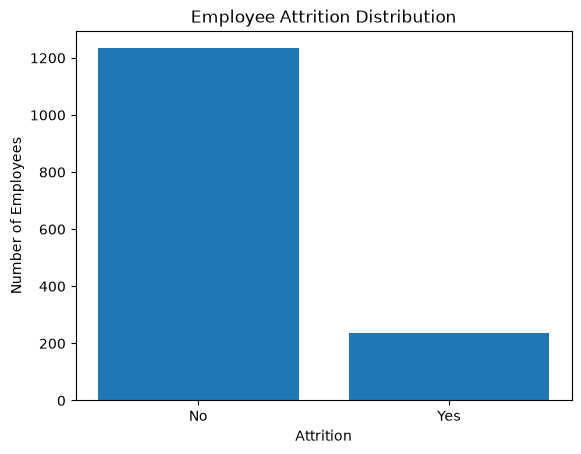

In [13]:

attrition = df["Attrition"].value_counts()

plt.bar(attrition.index, attrition.values)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

**Observation:** The dataset contains substantially more employees who did not leave than employees who left. Therefore, the target variable is imbalanced.

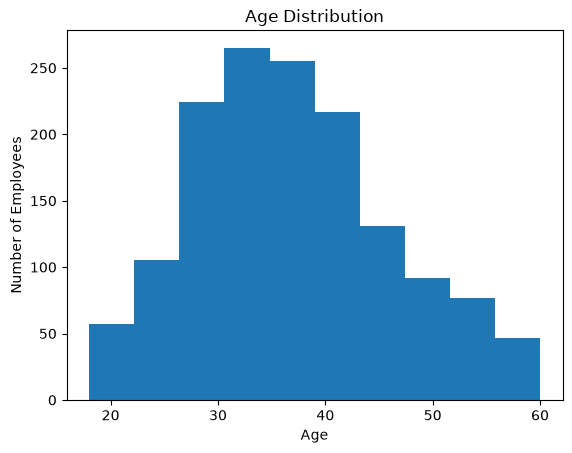

In [14]:
plt.hist(df["Age"], bins=10)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.show()

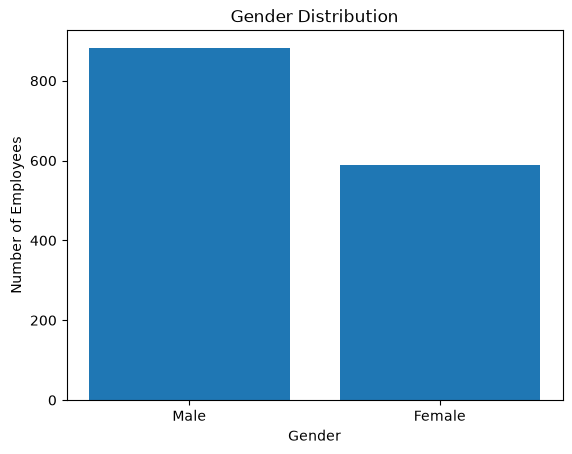

In [15]:
gender = df["Gender"].value_counts()

plt.bar(gender.index, gender.values)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")
plt.show()

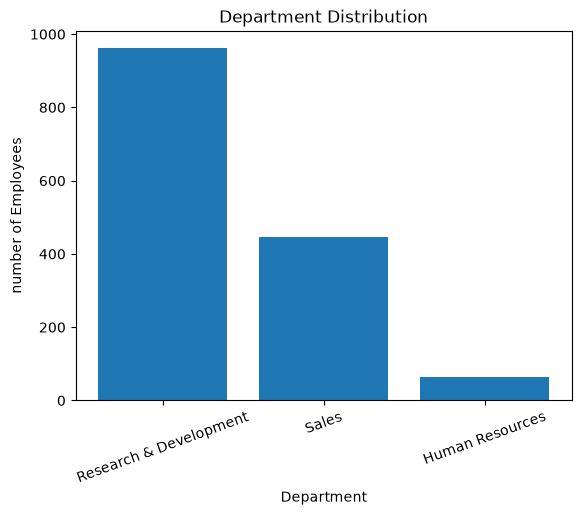

In [16]:
dept=df["Department"].value_counts()
plt.bar(dept.index,dept.values) 
plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("number of Employees")
plt.xticks(rotation=20)
plt.show()

### 3.2 Categorical Feature Analysis

We visualize important categorical variables to understand their distributions and investigate how employee characteristics vary across the dataset.

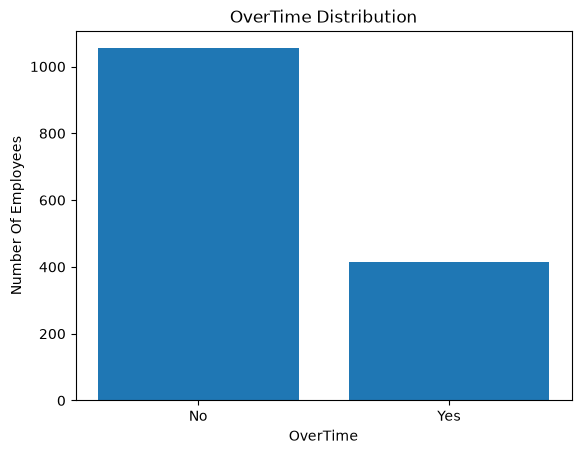

In [17]:
overtime=df["OverTime"].value_counts()
plt.bar(overtime.index,overtime.values)
plt.title("OverTime Distribution")
plt.xlabel("OverTime")
plt.ylabel("Number Of Employees")
plt.show()

### 3.3 Correlation Analysis

A correlation heatmap shows the strength and direction of relationships between numerical variables.

Correlation values range from -1 to +1:

- +1 indicates a strong positive relationship.
- -1 indicates a strong negative relationship.
- 0 indicates little or no linear relationship.

The heatmap helps us identify potentially related features and understand the numerical structure of the dataset.

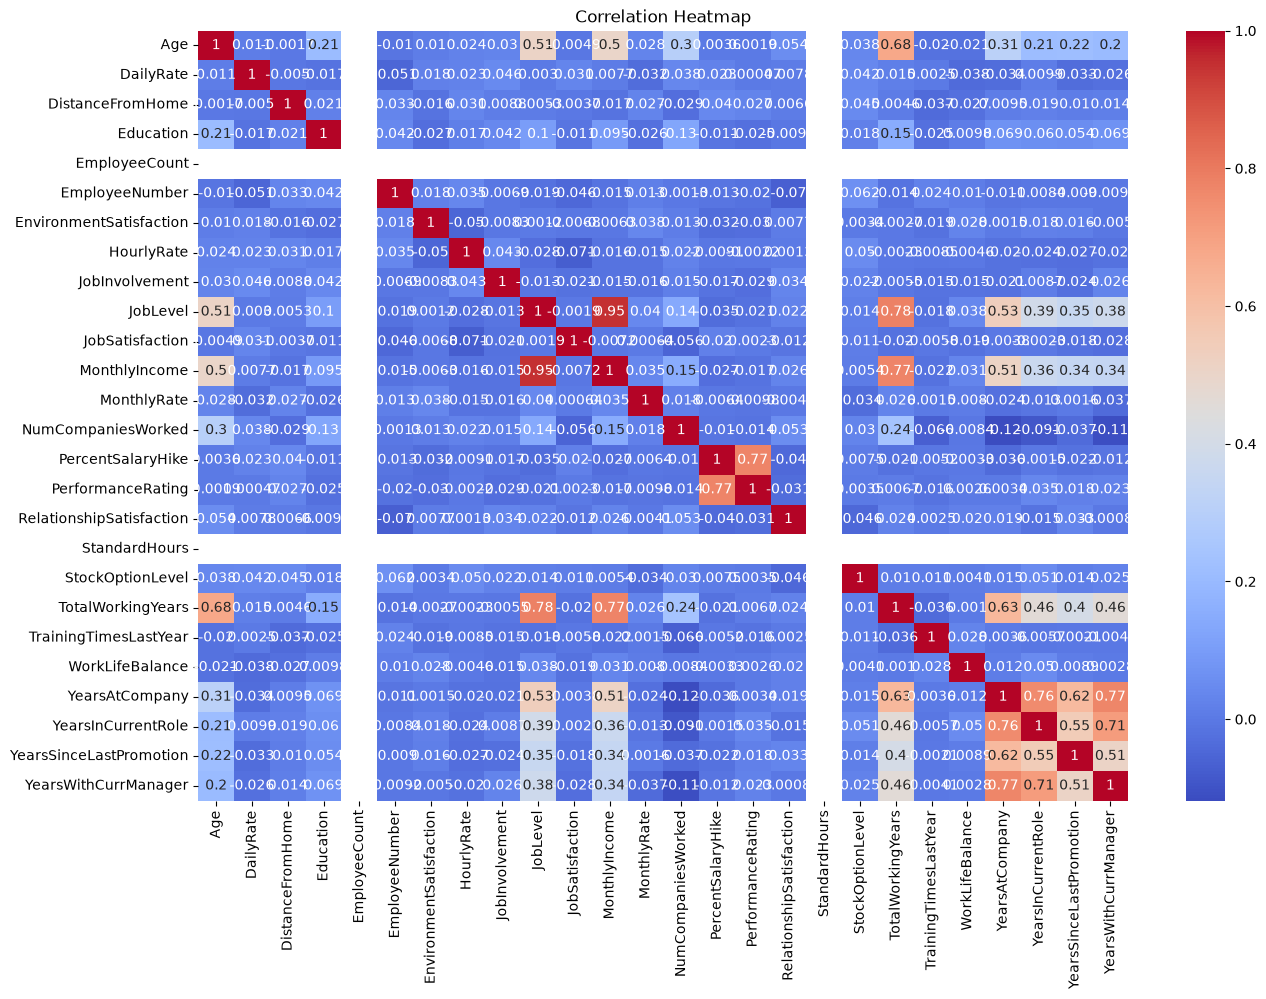

In [18]:
import seaborn as sns 
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm") 
plt.title("Correlation Heatmap")
plt.show()

###  Unique Value Analysis

We examine the number of unique values in each feature.

This helps identify categorical variables and features that contain only one unique value. Features with only one value do not provide useful information for prediction.

In [19]:
df.nunique() # will show how many unique values are there in each column

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

**Observation:** EmployeeCount, Over18, and StandardHours contain only one unique value and therefore do not provide useful information for prediction.

### 3.2 Attrition by Overtime

Overtime is an important workplace factor that may be associated with employee attrition. We compare attrition rates between employees who work overtime and those who do not.


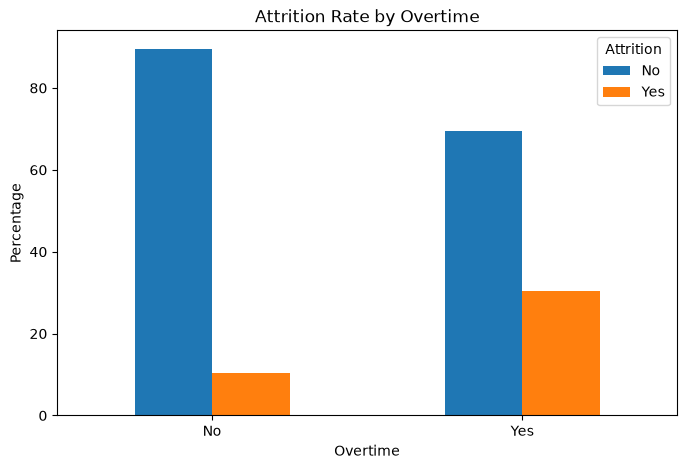

In [20]:
attrition_overtime = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

attrition_overtime.plot(kind="bar", figsize=(8,5))
plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Attrition")
plt.show()

### 3.3 Attrition by Job Satisfaction

Job satisfaction levels are compared with employee attrition to identify whether satisfaction differs between employees who stay and those who leave.


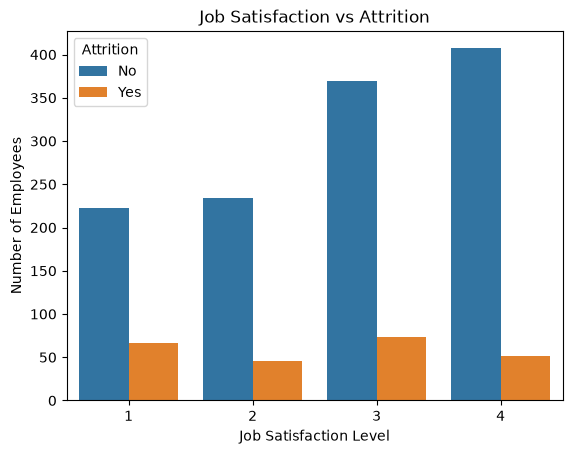

In [24]:
sns.countplot(data=df, x="JobSatisfaction", hue="Attrition")

plt.title("Job Satisfaction vs Attrition")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Number of Employees")
plt.show()

### 3.4 Attrition by Department

We compare employee attrition across departments to identify differences in attrition patterns among major organizational units.


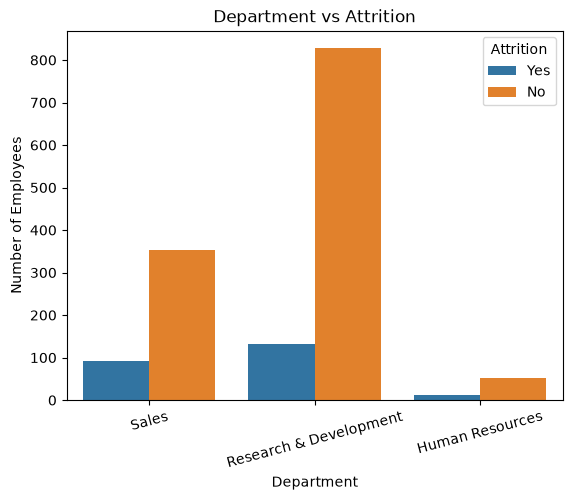

In [25]:
sns.countplot(data=df, x="Department", hue="Attrition")

plt.title("Department vs Attrition")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.show()

### 3.5 Age Distribution by Attrition

A box plot is used to compare the age distribution of employees who stayed with those who left.


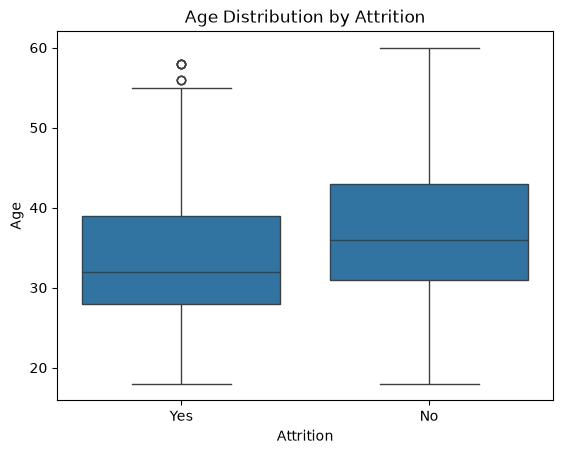

In [27]:
sns.boxplot(data=df, x="Attrition", y="Age")

plt.title("Age Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")
plt.show()

### Monthly Income vs Attrition

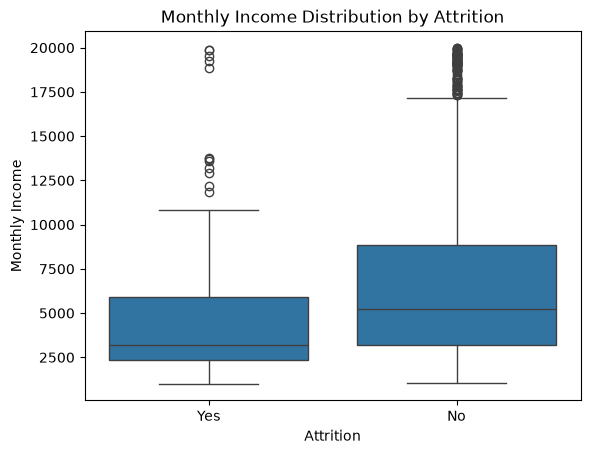

In [28]:
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.show()

### Distance From Home vs Attrition

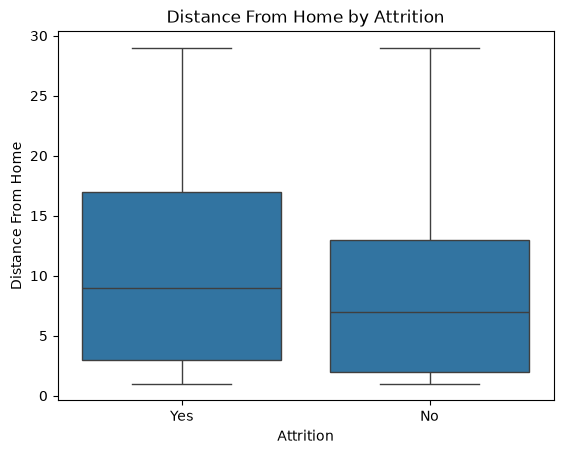

In [29]:
sns.boxplot(data=df, x="Attrition", y="DistanceFromHome")

plt.title("Distance From Home by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Distance From Home")
plt.show()

### Age vs Monthly Income

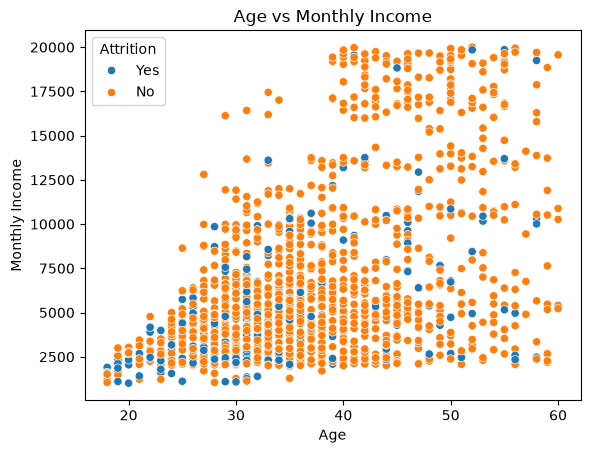

In [30]:
sns.scatterplot(
    data=df,
    x="Age",
    y="MonthlyIncome",
    hue="Attrition"
)

plt.title("Age vs Monthly Income")
plt.xlabel("Age")
plt.ylabel("Monthly Income")
plt.show()

### Years at Company vs Monthly Income

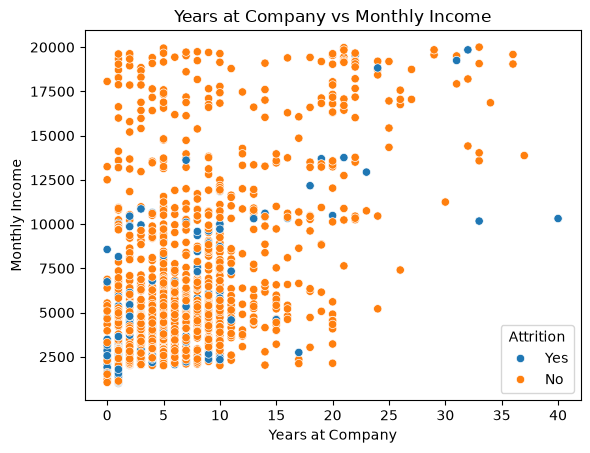

In [31]:
sns.scatterplot(
    data=df,
    x="YearsAtCompany",
    y="MonthlyIncome",
    hue="Attrition"
)

plt.title("Years at Company vs Monthly Income")
plt.xlabel("Years at Company")
plt.ylabel("Monthly Income")
plt.show()

## 4. Data Preprocessing

Before further analysis, we clean the dataset by removing irrelevant or constant-value features that do not contribute meaningful information to exploratory analysis

### 4.1 Removing Unnecessary Features

EmployeeCount, Over18, and StandardHours contain only one unique value, so they provide no useful variation for prediction.

EmployeeNumber is an identifier rather than a meaningful predictive feature, so it is also removed.

In [21]:
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])

In [22]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [23]:
df.shape

(1470, 31)

## 5. Outlier Analysis

Box plots help identify potential outliers in important numerical variables. Outliers are observations that fall unusually far from the typical range of the data.

We examine variables such as Age, MonthlyIncome, DistanceFromHome, and YearsAtCompany to understand their distributions and identify unusual observations.


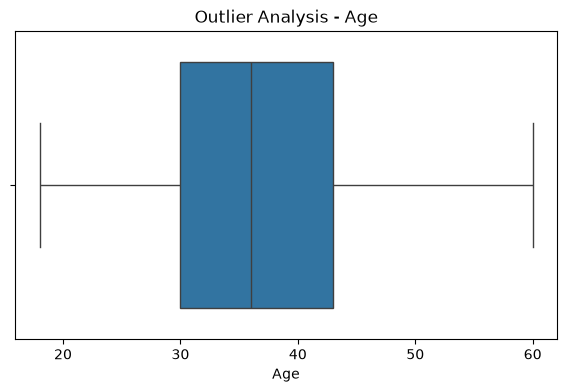

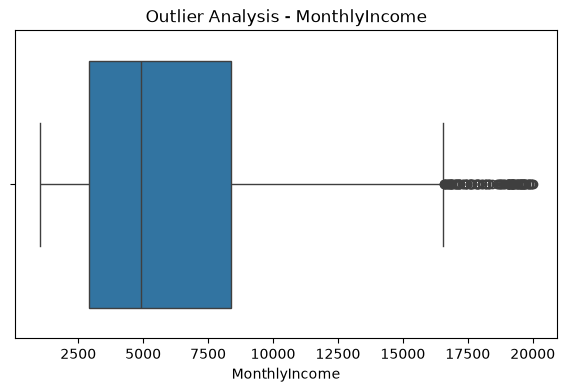

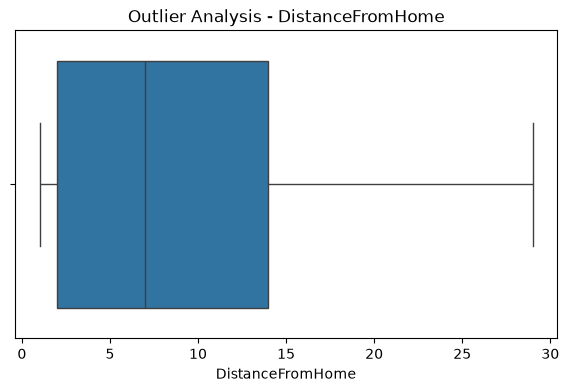

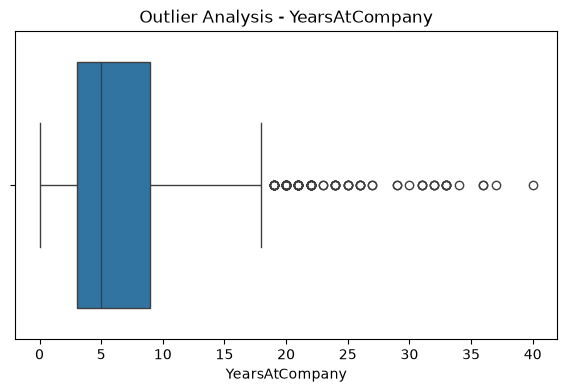

In [32]:
numerical_features = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "YearsAtCompany"
]

for feature in numerical_features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df[feature])
    plt.title(f"Outlier Analysis - {feature}")
    plt.xlabel(feature)
    plt.show()

## 6. Key Findings and Insights

Based on the exploratory analysis, the following patterns were observed:

* Employee attrition is unevenly distributed, with fewer employees leaving than staying.
* Overtime shows a noticeable relationship with employee attrition.
* Job satisfaction levels vary across employees with different attrition outcomes.
* Attrition patterns differ across departments.
* Age and monthly income distributions show differences between employees who stayed and those who left.
* Distance from home provides another useful factor for comparing employee groups.
* Years at the company and monthly income show a relationship that can be explored through scatter plots.
* The correlation analysis helps identify relationships among numerical workplace and employee characteristics.

### HR-Oriented Insights

The analysis can help HR teams investigate areas such as workload, employee satisfaction, compensation, career progression, and workplace conditions when studying employee retention.
